In [13]:
import numpy as np
import scipy
from scipy.stats import beta, boltzmann
from typing import Tuple
import sys
import os
import librosa
import matplotlib.pyplot as plt

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from modules.Pyin import PitchExtractor
from util import audio

pitch_extractor = PitchExtractor()

[-2.9673258e-05 -3.6110661e-05 -3.8504204e-05 ... -3.0914794e-05
 -2.9738290e-05 -3.2249300e-05]


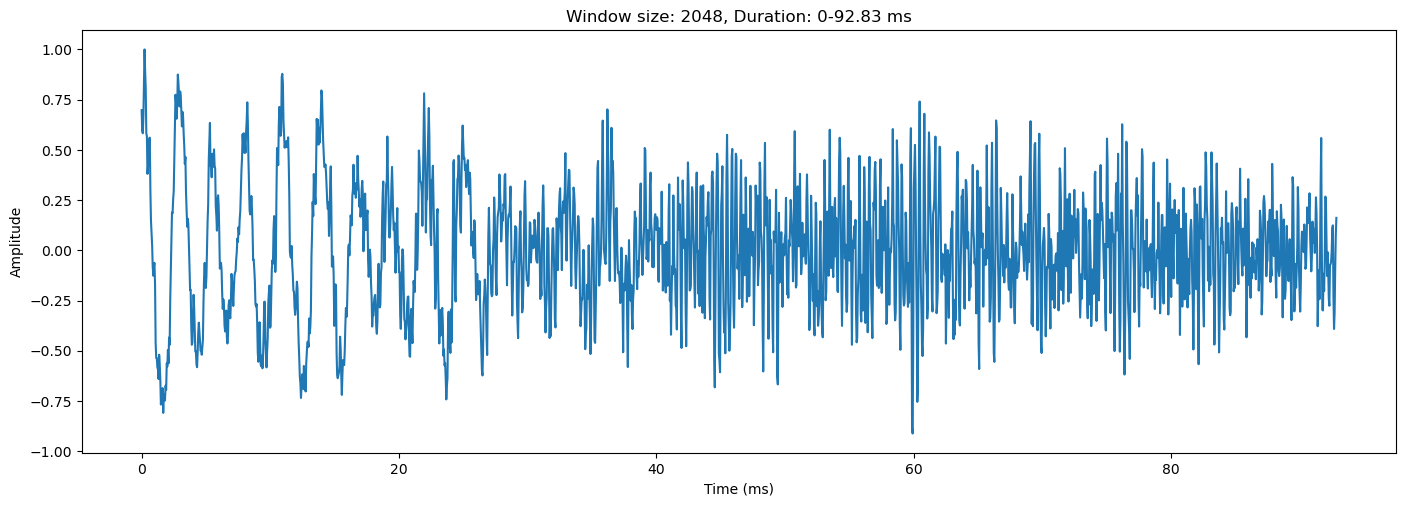

In [14]:
y, sr = librosa.load('./birds_of_feather.wav')
print(y)
windows_size = int(2048)
window_start = np.random.randint(0, len(y) - windows_size)
window_end = window_start + windows_size
window = y[window_start:window_end]
window = window / (np.max(np.abs(window)) + 1e-10) 

time_ms = np.arange(len(window)) * 1000 / sr

plt.figure(figsize=(14, 5))
plt.plot(time_ms, window)

plt.title(f'Window size: {windows_size}, Duration: 0-{time_ms[-1]:.2f} ms')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude')
plt.tight_layout(pad=0.5) # add padding to avoid overlap
plt.show()

[1.23217237 1.45015061 1.48562217 1.30908597 0.74352109 0.59399611
 0.57075369 0.59996808 1.10457957 1.13137388 1.2674278  1.23620188
 1.13015461 0.76308703 0.77286005 0.75399548 0.88350934 1.07234108
 1.18619537 1.15607691 0.79415387 0.700014   0.98487306 1.18638325
 1.27839673 0.65529221 0.68334877 0.76873839 0.7339384  0.88053602
 1.04259002]
6.501841930770344e-11
4.564647325137779e-09


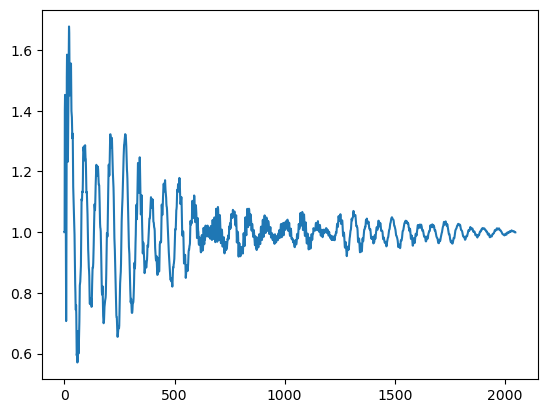

In [15]:
difference = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(difference)

plt.plot(cmndf)

original_local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
# print(original_local_minima)
# print(local_minima_index)
# print(pitch_extractor.min_lag)
# print(pitch_extractor.max_lag)
filtered_local_minima = pitch_extractor._filter_local_minimas(original_local_minima, local_minima_index)

local_minima, local_minimas_probs = pitch_extractor._assign_probabilities(filtered_local_minima)

from tests.test import PitchExtractor as PE
test_pitch_extractor = PE()

heights, probs = test_pitch_extractor._assign_probs(cmndf)

print(local_minima)
# print(heights)
print(np.sum(local_minimas_probs))
print(np.sum(probs))